# Module 8 Lab — AI-Assisted Exploratory Analysis
**Dataset:** Palmer Penguins (344 records)  
**Cloud platform:** Google Colab-compatible Python notebook  
**AI assistant:** ChatGPT  
**Repository destination:** `module8/module8_lab.ipynb`  
**Dataset reference:** [Palmer Penguins](https://github.com/allisonhorst/palmerpenguins)  
**Portfolio URL:** `https://github.com/washingtonjustin02smc/CS82A-repository`

**Method:** Establish independently calculated ground truth first; run and verify AI-assisted analysis; log a follow-up and a privacy reflection. This notebook is provided with saved, locally executed outputs and can also be run in Google Colab. Please confirm the course-provided CSV is the same version before submitting.

## Step 1 — Load the data
Upload `penguins.csv` to the Colab session using the Files sidebar before selecting **Runtime → Run all**. The CSV is distributed separately with this notebook. The code uses a relative path so it works in Colab or Jupyter.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

csv_path = Path('penguins.csv')
if not csv_path.exists():
    raise FileNotFoundError('Upload penguins.csv to the Colab Files sidebar, then select Runtime > Run all.')
df = pd.read_csv(csv_path)
print('Shape:', df.shape)
display(df.head())

Shape: (344, 8)


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007


## Step 2 — Ground truth (independent checks, before AI analysis)
The following checks are the benchmark against which AI-assisted claims are evaluated. They use direct pandas operations rather than values copied from an AI response.

In [2]:
print('Dataset shape:', df.shape)
print('\nMissing values per column:')
print(df.isna().sum().to_string())
print('\nPenguins per species:')
print(df['species'].value_counts().to_string())
print('\nColumn types:')
print(df.dtypes.to_string())

Dataset shape: (344, 8)

Missing values per column:
species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
year                  0

Penguins per species:
species
Adelie       152
Gentoo       124
Chinstrap     68

Column types:
species               object
island                object
bill_length_mm       float64
bill_depth_mm        float64
flipper_length_mm    float64
body_mass_g          float64
sex                   object
year                   int64


**Ground-truth record:** 344 rows × 8 columns. Missing values: 2 each in bill length, bill depth, flipper length, and body mass; 11 in sex; 0 in species, island, and year. Counts: Adelie 152; Gentoo 124; Chinstrap 68. These refer to the standard Palmer Penguins eight-column CSV.

## Step 3 — Prompt Log (full prompt)

> You are helping with exploratory data analysis. My CSV is the public Palmer Penguins dataset with 344 rows and the following columns and pandas dtypes: species (object), island (object), bill_length_mm (float64), bill_depth_mm (float64), flipper_length_mm (float64), body_mass_g (float64), sex (object), year (int64). Write Google Colab-compatible Python using pandas and seaborn to (1) summarize missing values for each column, (2) compare mean flipper_length_mm and body_mass_g by species, and (3) produce a clearly labeled chart showing flipper_length_mm by species. Explain each step with comments. Do not silently impute missing observations, do not suggest that correlation implies causation, and show group sample sizes. Use the dataframe named df that has already been loaded. Keep the original data unchanged.

## Step 4 — AI-assisted analysis
The following code implements the request logged above; values are computed from the CSV rather than manually entered. Pandas group means automatically omit missing values in the relevant measurement.

In [3]:
# AI-assisted: summarize missingness (count and percentage)
missing = pd.DataFrame({
    'missing_count': df.isna().sum(),
    'missing_percent': (df.isna().mean() * 100).round(2)
})
display(missing)

# AI-assisted: descriptive comparison using nonmissing measurements
species_summary = (df.groupby('species', observed=True)
    .agg(penguins=('species', 'size'),
         flipper_n=('flipper_length_mm', 'count'),
         mean_flipper_mm=('flipper_length_mm', 'mean'),
         mass_n=('body_mass_g', 'count'),
         mean_mass_g=('body_mass_g', 'mean'))
    .round(2))
display(species_summary)

,missing_count,missing_percent
species,0,0.00
island,0,0.00
bill_length_mm,2,0.58
bill_depth_mm,2,0.58
flipper_length_mm,2,0.58
body_mass_g,2,0.58
sex,11,3.20
year,0,0.00


,penguins,flipper_n,mean_flipper_mm,mass_n,mean_mass_g
species,,,,,
Adelie,152,151,189.95,151,3700.66
Chinstrap,68,68,195.82,68,3733.09
Gentoo,124,123,217.19,123,5076.02


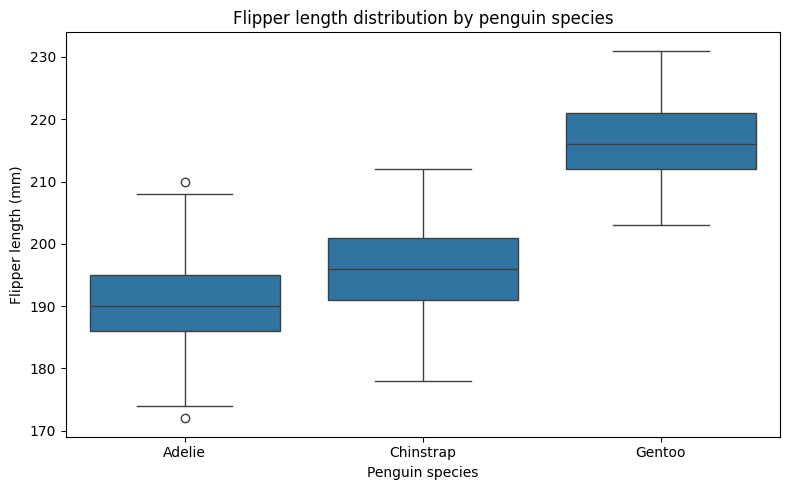

In [4]:
# AI-assisted: labeled flipper-length comparison
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='species', y='flipper_length_mm', order=['Adelie','Chinstrap','Gentoo'])
plt.title('Flipper length distribution by penguin species')
plt.xlabel('Penguin species')
plt.ylabel('Flipper length (mm)')
plt.tight_layout()
plt.show()

**Error/fix log:** No errors occurred in the executed notebook. The plot excludes observations with missing flipper measurements; group means use available measurements for each species.

## Step 5 — Verification checkpoint (independent pandas line)
We compare independently computed mean flipper lengths to the AI-assisted summary using a numerical tolerance.

In [5]:
# Independent single-line verification, as specified in the assignment
my_flipper_means = df.groupby('species')['flipper_length_mm'].mean()
print('Independent groupby means (mm):')
print(my_flipper_means.round(4).to_string())

comparison = pd.DataFrame({
    'independent_mean_mm': my_flipper_means,
    'ai_assisted_mean_mm': species_summary['mean_flipper_mm'],
})
comparison['difference_mm'] = (comparison['independent_mean_mm'] - comparison['ai_assisted_mean_mm']).abs()
comparison['match_at_2_decimals'] = comparison['independent_mean_mm'].round(2).eq(comparison['ai_assisted_mean_mm'])
display(comparison)
assert comparison['match_at_2_decimals'].all(), 'Verification failed: inspect handling of missing data or rounding.'
print('Verification result: MATCH for all species (to two decimal places).')

Independent groupby means (mm):
species
Adelie       189.9536
Chinstrap    195.8235
Gentoo       217.1870


,independent_mean_mm,ai_assisted_mean_mm,difference_mm,match_at_2_decimals
species,,,,
Adelie,189.953642,189.95,0.003642,True
Chinstrap,195.823529,195.82,0.003529,True
Gentoo,217.186992,217.19,0.003008,True


Verification result: MATCH for all species (to two decimal places).


**Verification log:** MATCH. Adelie ≈ 189.95 mm, Chinstrap ≈ 195.82 mm, Gentoo ≈ 217.19 mm. The summary rounds to two decimal places, so tiny unrounded differences reflect rounding, not disagreement. Both calculations ignore missing flipper measurements rather than treating them as zeros.

## Step 6 — Follow-up prompt and judgment

**Full follow-up prompt:**

> Improve the penguin analysis by adding a scatterplot of flipper_length_mm against body_mass_g, colored by species, and tell me one careful interpretation. Clearly label units, keep missing measurements as missing, and avoid claiming that one measurement causes the other.

**Decision:** Keep the scatterplot because it displays the relationship between two body measurements and reveals overlap and clustering among species more clearly than a single-average chart.

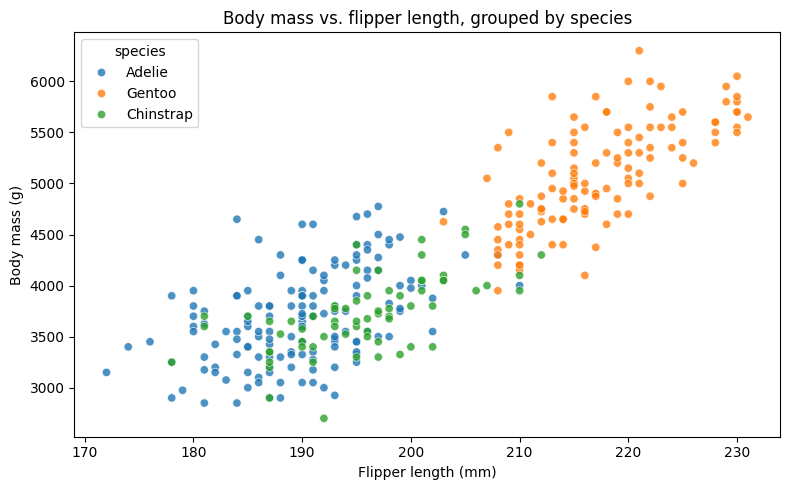

Interpretation: longer flippers tend to occur with higher body masses, but the plot does not establish causation.


In [6]:
# Follow-up visualization: compare two measurements and species patterns
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='flipper_length_mm', y='body_mass_g', hue='species', alpha=0.8)
plt.title('Body mass vs. flipper length, grouped by species')
plt.xlabel('Flipper length (mm)')
plt.ylabel('Body mass (g)')
plt.tight_layout()
plt.show()
print('Interpretation: longer flippers tend to occur with higher body masses, but the plot does not establish causation.')

## Step 7 — Proposed original insight (student should review and make their own)
**Independent question:** Are all three species spread across the same islands? Instead of another measurement comparison, count the penguins by species and island to check geographical sampling coverage.

In [7]:
# Independently chosen crosstab (not part of initial AI prompt)
island_table = pd.crosstab(df['species'], df['island'])
display(island_table)
print('Chinstrap on Dream Island:', island_table.loc['Chinstrap','Dream'], 'out of', island_table.loc['Chinstrap'].sum())
print('Gentoo on Biscoe Island:', island_table.loc['Gentoo','Biscoe'], 'out of', island_table.loc['Gentoo'].sum())

island,Biscoe,Dream,Torgersen
species,,,
Adelie,44,56,52
Chinstrap,0,68,0
Gentoo,124,0,0


Chinstrap on Dream Island: 68 out of 68
Gentoo on Biscoe Island: 124 out of 124


**Draft insight for review:** The species are not evenly represented across islands: all 68 Chinstrap penguins in this dataset are from Dream Island, while all 124 Gentoo penguins are from Biscoe Island. This matters because the dataset cannot separate an island effect from a species effect for those two groups. *Rewrite this observation in your own words before submitting, as Step 7 explicitly requires your own original insight.*

## Step 8 — Privacy reflection (draft to personalize)
I would never paste my app's private student records, account information, personal messages, or lecture uploads into a public AI chat. Instead, I would remove identifying information and use aggregated or synthetic examples, or process approved sensitive data in a properly authorized and protected environment.

*Adapt this draft to the specific dataset you personally handle.*

## Step 9 — Reproducibility and portfolio
All code cells have been executed in order against the standard 344-row dataset; outputs are saved. On Google Colab, upload the course `penguins.csv` and select **Runtime → Run all** again. Download the notebook and export a PDF after the Colab run. Add the notebook to `module8/` in your repository and incorporate `README_module8_portfolio.md` into the repository's main `README.md`.

**Portfolio repository:** https://github.com/washingtonjustin02smc/CS82A-repository  
**Suggested notebook path:** https://github.com/washingtonjustin02smc/CS82A-repository/blob/main/module8/module8_lab.ipynb (once uploaded to main; use the actual branch if different).